Ноутбук служит основой для изучения, однако многое нужно будет поискать и почитать самостоятельно
***

# Часть 1 (6+ pt)

В этом домашнем задании вы познакомитесь с **разведовательным анализом** (EDA). На самом деле, разведывательный анализ — это не что-то съверхестественное. Более того, в предыдущих заданиях вы уже в какой-то мере его совершали.

**EDA (Exploratory Data Analysis)** — это первый и критически важный этап работы с данными, на котором вы «знакомитесь» с набором данных через визуализации и статистические резюме. Через EDA:
> - Обнаруживаете аномалии и пропуски
> - Понимаете распределение признаков
> - Выявляете взаимосвязи между переменными
> - Формулируете гипотезы для дальнейшей проверки

Звучит знакомо, правда?

Поэтому в этой домашке мы скорее соберем все навыки воедино и дополним их **статистикой** и **визуализацией**!

Будем руководствоваться следующими вопросами:
* Как распределены значения признаков?
* Какие признаки связаны между собой?
* Какие закономерности скрыты в данных?
* Какие гипотезы можно сформулировать для дальнейшего анализа?

В ноутбуке как всегда будут теоретические справки, но полезно еще почитать [Seaborn Tutorial](https://seaborn.pydata.org/tutorial.html?spm=a2ty_o01.29997173.0.0.33be5171FMA4h7),
[Understanding Correlation](https://seaborn.pydata.org/examples/many_pairwise_correlations.html?spm=a2ty_o01.29997173.0.0.33be5171FMA4h7),
[Pandas Statistical Functions](https://pandas.pydata.org/docs/reference/general_functions.html?spm=a2ty_o01.29997173.0.0.33be5171FMA4h7#computational-descriptive-stats).

***
В этой части будем использовать датасет `diamonds` из `seaborn` (значения столбцов можно посмотреть в интернетах). Мы уже умеем загружать такие датасеты, сделаем это.

In [1]:
# Используем pandas, numpy, seaborn, matplotlib и scipy.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print(f"Pandas version: {pd.__version__}")
print(f"Seaborn version: {sns.__version__}")
from IPython.display import display

Pandas version: 3.0.6
Seaborn version: 0.13.2


In [3]:
diamonds = sns.load_dataset('diamonds')
diamonds.shape

(53940, 10)

### Знакомство с данными (1 pt)

**ЗАДАНИЕ: базово исследуйте и очистите данные, напишите небольшой вывод.**

Можете ориентироваться на следующие важные пункты:
* Столбцы, их значение и типы их значений
* Количество уникальных значений
* Границы значений
* Пропуски
* Дубликаты

In [4]:
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
diamonds.info()
print('-----------------------')
print(diamonds.describe())
print('-----------------------')
print(diamonds.isnull().sum())
print('-----------------------')
print(diamonds.duplicated().sum())
print('-----------------------')
print(diamonds.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
-----------------------
              carat         depth         table         price             x  \
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000   
mean       0.797940     61.749405     57.457184   3932.799722      5.731157   
std        0.474011      1.432621      2.234491   3989.439738      1.121761   
min        0.200000     43.0000

Датасет содержит 53940 строк и 10 столбцов: 7 числовых и 3 категориальных. Пропусков нет, есть 146 полных повторов.
Повторы оставляю: без ID нельзя понять, это дубли записей или разные камни с одинаковыми характеристиками.
20 строк с нулевыми размерами удаляю, такие размеры невозможны.

In [6]:
diamonds_raw = diamonds.copy()
invalid_dimensions = diamonds[['x', 'y', 'z']].le(0).any(axis=1)
diamonds = diamonds.loc[~invalid_dimensions].copy()
print('Удалено строк с нулевыми размерами:', int(invalid_dimensions.sum()))
print('Осталось строк:', len(diamonds))

# Проверяем крайние размеры отдельно, не удаляем все выбросы автоматически.
display(diamonds.nlargest(3, 'y')[['carat', 'depth', 'x', 'y', 'z']])
display(diamonds.nlargest(3, 'z')[['carat', 'depth', 'x', 'y', 'z']])

Удалено строк с нулевыми размерами: 20
Осталось строк: 53920


,carat,depth,x,y,z
24067,2.00,58.9,8.09,58.90,8.06
49189,0.51,61.8,5.15,31.80,5.12
27415,5.01,65.5,10.74,10.54,6.98


,carat,depth,x,y,z
48410,0.51,61.8,5.12,5.15,31.80
24067,2.00,58.9,8.09,58.90,8.06
27415,5.01,65.5,10.74,10.54,6.98


У y и z есть подозрительные значения 31.8 и 58.9. Оставляю их без исправления: правильные размеры неизвестны. Они могут сильно влиять на асимметрию y и z.

### Одномерный анализ (3 pt)

После того, как вы «окинули взглядом» данные и применили те методы, которые уже знаете, перейдем к статистическому анализу и более глубокому пониманию.

В этом пункте мы поговорим про **одномерный анализ**, то есть про анализ каждого признака по отдельности _(можно найти и другие определения, не претендую на единсвенно верное)_.

Важными для одномерного анализа являются **мера центральности** и **мера разброса**, а также сама форма распределений. Давайте поговорим про них по отдельности.

***
Центрирование данных можно описать через три ключевые меры:
| Мера | Функция | Когда использовать |
| ---- | ------- | ------------------ |
| **Среднее** | `.mean()` | Для симметричных распределений без выбросов |
| **Медиана** | `.median()` | Для асимметричных распределений или при наличии выбросов |
| **Мода** (наиболее частое значение) | `.mode()` | Для категориальных данных или мультимодальных распределений |

Все три меры, безусловно, дают нам информацию о распределении данных и мы можем делать из этого выводы (например если среднее сильно отличается от медианы). Однако пукнт _«Когда использовать»_ говорит о том, когда эту меру стоит использовать для информативного описания распределения в дальнейшем (или для использования статистики при каких-то вычислениях).

In [7]:
# ЗАДАНИЕ:
#          1. Рассчитайте подходящие статистики для каждого из столбцов.
#          2. Объясните расхождения между средним и медианой, если такие есть.
#          3. Напишите вывод (ваши гипотезы) о распределении данных на основе мер центральности.

numeric = diamonds.select_dtypes(include=np.number)
print(numeric.agg(['mean', 'median']).T)
print('-----------------------')
print(diamonds[['cut', 'color', 'clarity']].mode())

              mean   median
carat     0.797698     0.70
depth    61.749514    61.80
table    57.456834    57.00
price  3930.993231  2401.00
x         5.731627     5.70
y         5.734887     5.71
z         3.540046     3.53
-----------------------
     cut color clarity
0  Ideal     G     SI1


_Почему для цены среднее > медианы? Что это говорит о распределении цен?_

Наибольшая разница среднего и медианы у цены: 3931 и 2401. Дорогие камни тянут среднее вверх, поэтому медиана лучше описывает типичную цену.

***
Одной меры центральности недостаточно для описания распределения. Еще одной важной мерой для описания данных является **мера разброса** _(мы уже немного затрагивали эту тему, когда говорили про выявление аномалий)_, а также понимание пормы распределения.

Для описания разброса и формы данных можно использовать следующие статистики:

| Статистика | Функция | Описание | Интерпретация |
| ---------- | ------- | -------- | ------------- |
| **Дисперсия** | `.var()` | Обычная дисперсия | Среднее квадратов отклонения от среднего |
| **Стандартное отклонение** | `.std()` | Корень из дисперсии | Типичное отклонение от среднего |
| **Межквартильный размах (IQR)** | `.quantile()` | $IQR=Q3−Q1$ | Размах "центральных" 50% данных |
| **Асимметрия (skewness)** | `.skew()` | $\frac{1}{n} \sum\limits_{i=1}^n \Big( \frac{x_i - \tilde{x}}{\sigma} \Big)^3$ | >0: правый хвост длиннее; <0: левый хвост длиннее |
| **Эксцесс (kurtosis)** | `.kurtosis()` | $\frac{1}{n} \sum\limits_{i=1}^n \Big( \frac{x_i - \tilde{x}}{\sigma} \Big)^4 - 3$ | >0: островершинное; <0: плосковершинное |

Как всегда документация: [.var()](https://pandas.pydata.org/docs/reference/api/pandas.Series.var.html),
[.std()](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html),
[.quantile()](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html),
[.skew()](https://pandas.pydata.org/docs/reference/api/pandas.Series.skew.html),
[.kurtosis()](https://pandas.pydata.org/docs/reference/api/pandas.Series.kurtosis.html),
[и про эксцесс](https://ru.wikipedia.org/wiki/%D0%9A%D0%BE%D1%8D%D1%84%D1%84%D0%B8%D1%86%D0%B8%D0%B5%D0%BD%D1%82_%D1%8D%D0%BA%D1%81%D1%86%D0%B5%D1%81%D1%81%D0%B0).

In [8]:
# ЗАДАНИЕ:
#          1. Рассчитайте подходящие статистики для каждого из столбцов.
#          2. Напишите вывод о распределении данных, сходится ли это с выводами прошлого пункта?

numeric = diamonds.select_dtypes(include=np.number)

stats = numeric.agg(['var', 'std', 'skew', 'kurt']).T
stats['IQR'] = numeric.quantile(0.75) - numeric.quantile(0.25)

stats 

,var,std,skew,kurt,IQR
carat,2.244820e-01,0.473795,1.116207,1.255240,0.64
depth,2.051572e+00,1.432331,-0.081726,5.746307,1.50
table,4.991043e+00,2.234064,0.796799,2.801738,3.00
price,1.589841e+07,3987.280446,1.618349,2.178391,4374.25
x,1.253107e+00,1.119423,0.398348,-0.703561,1.83
y,1.299887e+00,1.140126,2.462211,91.826238,1.82
z,4.935489e-01,0.702530,1.585490,47.764571,1.13


_Как асимметрия > 1 влияет на выбор меры центральной тенденции?_

У цены правая асимметрия, skew = +1.62, у carat — +1.12. У table асимметрия умеренная, x слабее, depth близок к симметричному. У y и z skew = +2.46 и +1.59, на них влияют крайние значения. При skew > 1 медиана устойчивее среднего.

***
Теперь когда мы поняли, как статистики помогают понять распределения попробуем их **визуализировать** и сравнить выводы.

<div class="alert alert-info">
<i>В этом задании мы действуем в такой последовательности в учебных целях, однако визуализацию можно и нужно применять раньше! Скорее именно ее стоит использовать для выдвижения гипотез, а статистиками гипотезы подтверждать. В части 2 и дальнейших исследованиях стоит делать именно так</i> 
</div>

**Разные типы графиков показывают разные аспекты распределения:**

| Тип графика | Что показывает | Когда использовать |
| ----------- | -------------- | ------------------ |
| **Гистограмма** | Частота значений в интервалах | Общий обзор формы распределения |
| **KDE-plot** | Сглаженная оценка плотности | Сравнение нескольких распределений |
| **Boxplot** | Медиана, квартили, выбросы | Сравнение распределений по категориям |
| **Violinplot** | Комбинация boxplot + KDE | Детальное сравнение форм распределений |

Про применение и параметры в документации: [sns.histplot()](https://seaborn.pydata.org/generated/seaborn.histplot.html),
[sns.kdeplot()](https://seaborn.pydata.org/generated/seaborn.kdeplot.html),
[sns.boxplot()](https://seaborn.pydata.org/generated/seaborn.boxplot.html),
[sns.violinplot()](https://seaborn.pydata.org/generated/seaborn.violinplot.html).

В следующем домашнем задании мы подробнее остановимся на построении красывых графиков, поэтому не стоит заморачиваться в этом задании. Однако важно всегда придерживаться **баловых правил**:
* должно быть **понятно**, что изображено на графике;
* должны присутствовать **названия осей** (за исключением, когда это очевидно);
* если на графике присутствуют разные данные, то должна быть **легенда**.

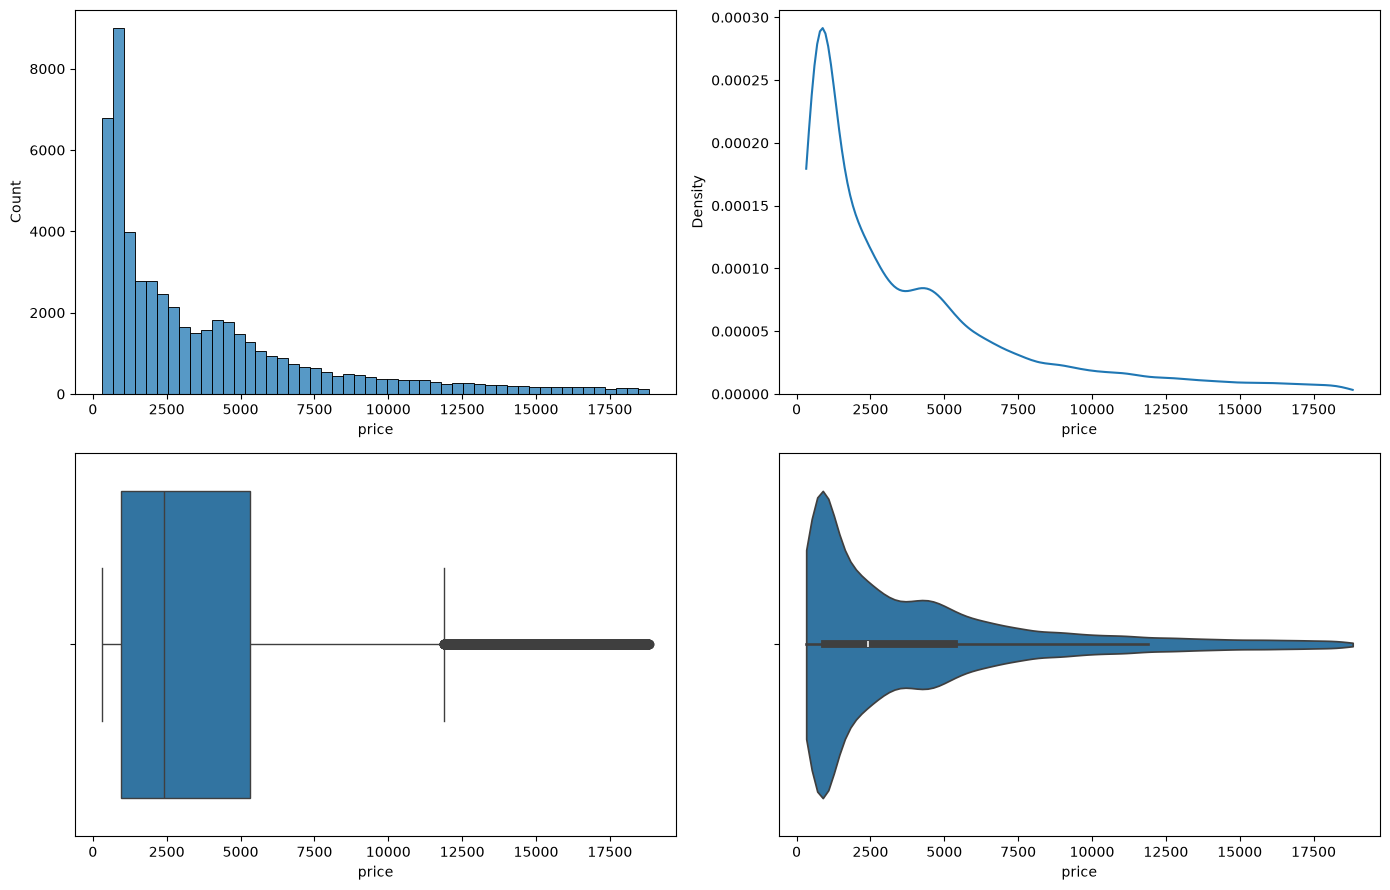

In [9]:
# ЗАДАНИЕ:
#          1. Постройте 4 типа визуализации для столбца 'price'.
#          2. Подтвердите (или опровергните) выводы предыдущих пунктов о распределениях других столбцов.
#          3. Напишите итоговый вывод о распределении данных.

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(data=diamonds, x='price', bins=50, ax=axes[0, 0])
sns.kdeplot(data=diamonds, x='price', cut=0, ax=axes[0, 1])
sns.boxplot(data=diamonds, x='price', ax=axes[1, 0])
sns.violinplot(data=diamonds, x='price', cut=0, ax=axes[1, 1])

plt.tight_layout()
plt.show()

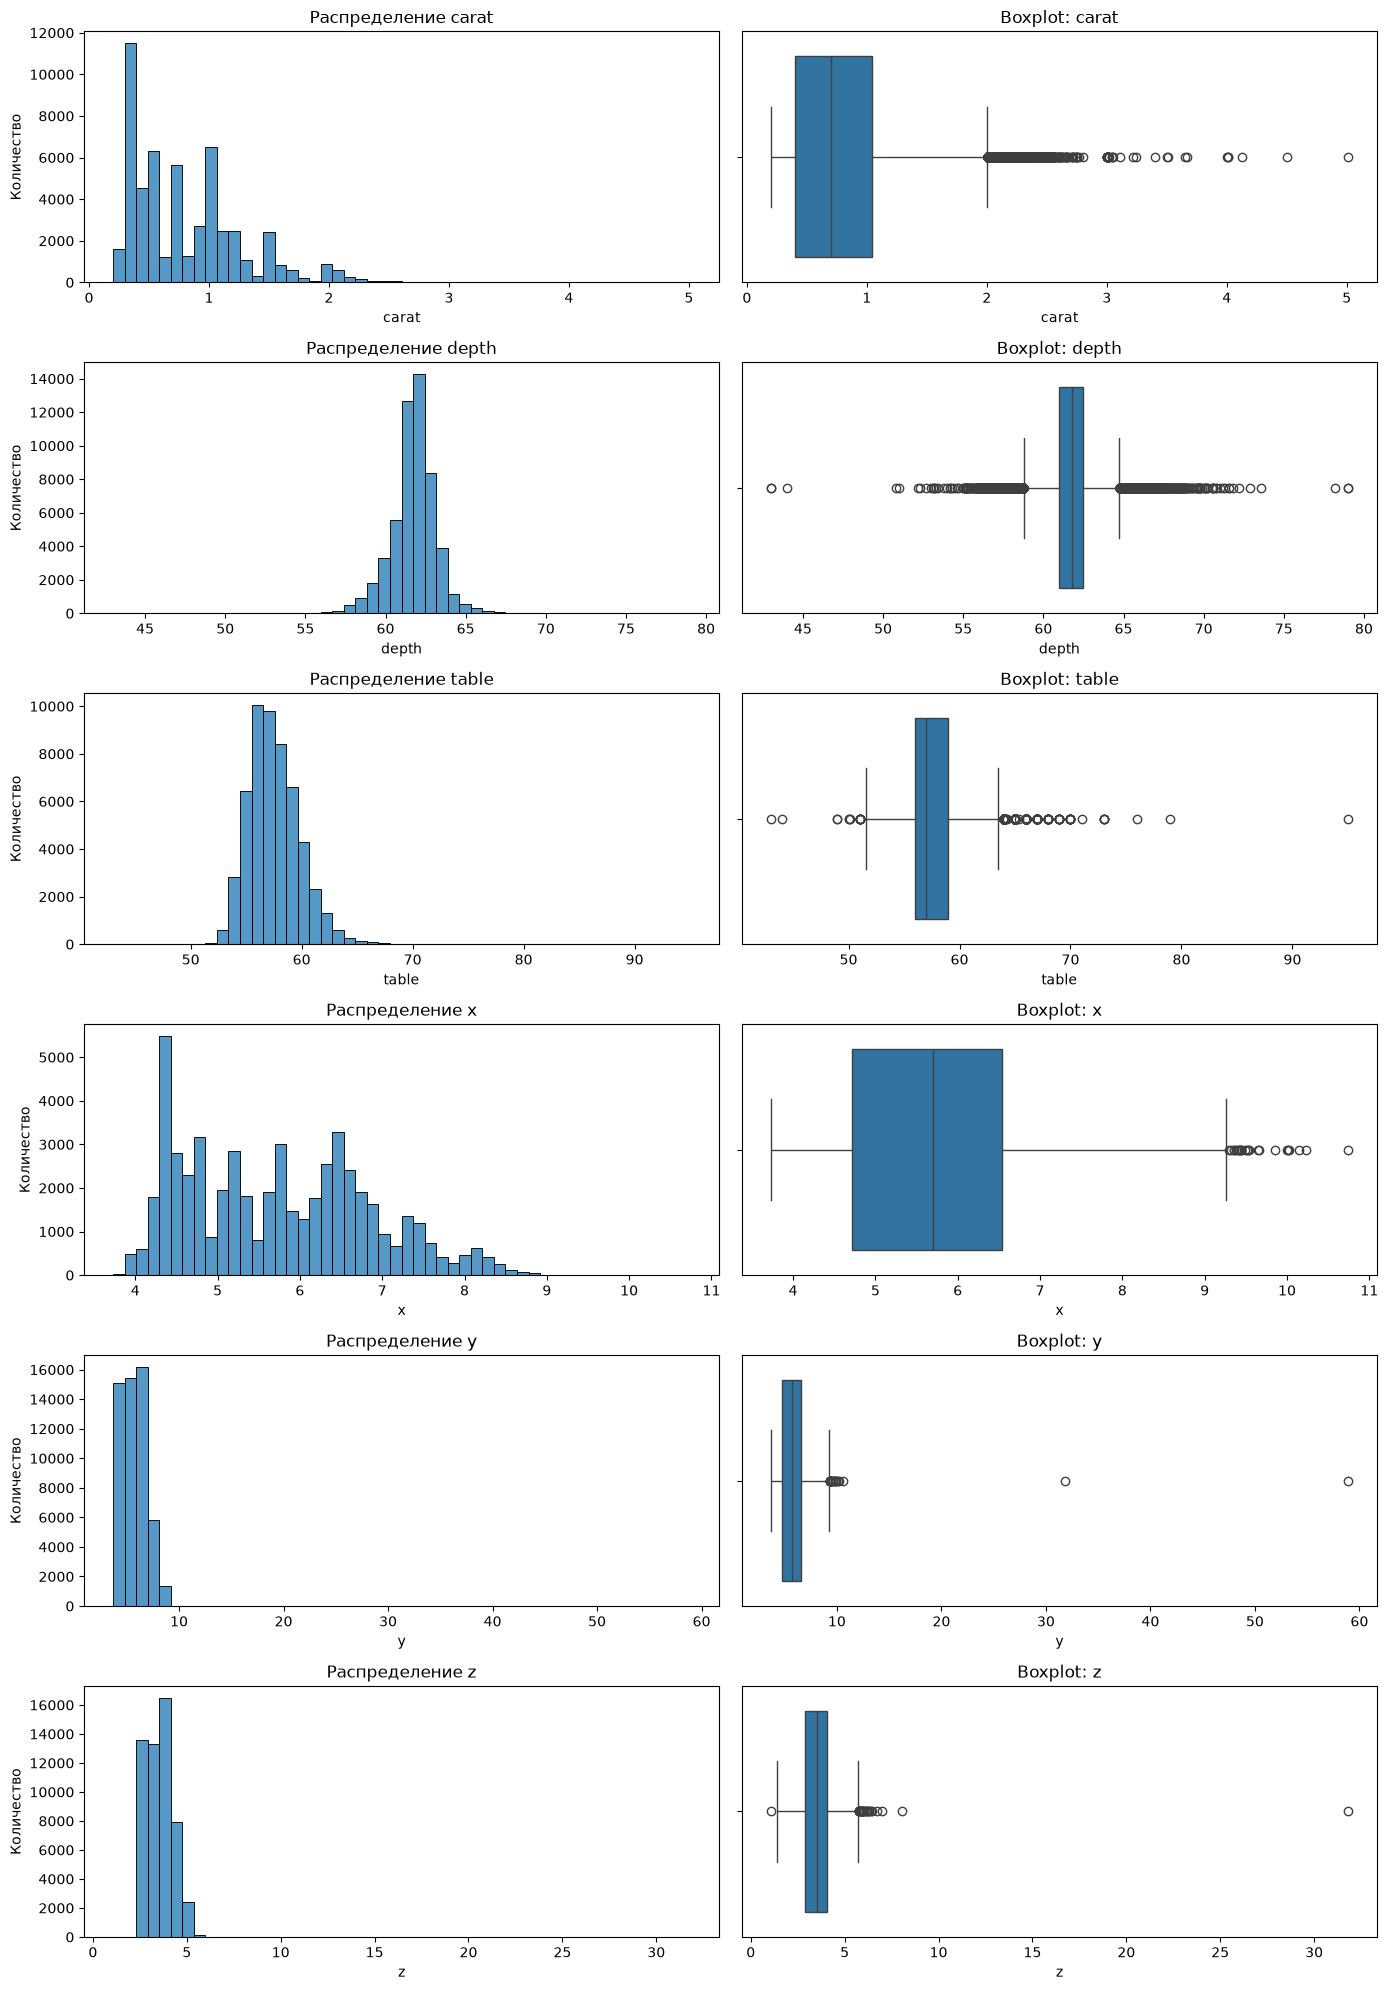

In [10]:
columns = ['carat', 'depth', 'table', 'x', 'y', 'z']
fig, axes = plt.subplots(len(columns), 2, figsize=(14, 20))

for row, column in enumerate(columns):
    sns.histplot(
        data=diamonds, x=column, bins=50,
        ax=axes[row, 0]
    )
    sns.boxplot(
        data=diamonds, x=column,
        ax=axes[row, 1]
    )

    axes[row, 0].set_title(f'Распределение {column}')
    axes[row, 0].set_ylabel('Количество')
    axes[row, 1].set_title(f'Boxplot: {column}')

plt.tight_layout()
plt.show()

Графики подтверждают статистики. Цена и масса имеют правую асимметрию. У table она умеренная, у x слабее, depth близок к симметричному. У carat и x видны пики. Нулевые размеры удалены, крайние значения y и z сохранены.

_Какой график лучше всего показывает асимметрию распределения? Какой график лучше выявляет выбросы? Почему для цен бриллиантов медиана — более репрезентативная мера, чем среднее?_

1. Асимметрию лучше видно на гистограмме и KDE.
2. Крайние значения лучше видно на boxplot.
3. Дорогие камни тянут среднее вверх, поэтому медиана лучше описывает типичную цену.

### Двумерный анализ (2 pt)

После того, как вы подробно изучили распределение каждого из признаков, перейдем к изучению «влияния» признаков друг на друга. 

**Двумерный анализ** — анализ взаимосвязи призваков друг с другом.  
Самым простым подходом является анализ **распределения одного признака в зависимости от значения другого** (например распределение цены для разной огранки), однако вы уже должны быть способны это сделать (условная фильтрация в pandas + визуализация распределения), поэтому останавливаться на этом мы сейчас не будем. _Но обязательно примените этот анализ во второй части!_

***

В этом задании остановимся на анализе **корреляций** признаков. Важно помнить, что **корреляция $\neq$ причинно-следственная связь**! Корреляция измеряет силу и направление связи между двумя числовыми признаками.

**Будем рассматривать два типа корреляции** (подробнее про [корреляцию](https://ru.wikipedia.org/wiki/%D0%9A%D0%BE%D1%80%D1%80%D0%B5%D0%BB%D1%8F%D1%86%D0%B8%D1%8F) в интренетах или на матстате):

| Тип корреляции | Что это такое | Когда использовать |
| -------------- | -------------- | ------------------ |
| **Пирсона** | 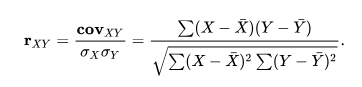 | Для линейных связей в нормально распределенных данных |
| **Спирмена** | Корреляция рангов | Для монотонных (не обязательно линейных) связей, устойчива к выбросам |

Документация: [.corr()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html),
[.spearmanr()](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

Корреляцию можно интерпретировать по-разному (разные градации/шкалы), но в целом логика такая: чем больше, тем сильнее величины связаны, если знак отрицательный, то «рост» одной связан с «падением» другой.

In [11]:
# Нетрудно заметить, что корреляция работает только для числовых признаков,
# поэтому выберем только числовые столбцы из данных

numeric_diamonds = diamonds.select_dtypes(include=[np.number])
pearson = numeric_diamonds.corr(method='pearson')
print(pearson)
print('---------------------')
# ЗАДАНИЕ:
#          1. Рассчитайте матрицу корреляций Пирсона для числовых признаков
#          2. Найдите пару признаков с самой сильной положительной корреляцией
#          3. Рассчитайте корреляцию Спирмена для этой же пары признаков
#          4. Сравните значения Пирсона и Спирмена — отличаются ли они, почему?

pairs = pearson.where(np.triu(np.ones(pearson.shape, dtype=bool), k=1)).stack()
pair = pairs.idxmax()

print(pair)
print('---------------------')
print(pairs.loc[pair])
print('---------------------')

first, second = pair
spearman = numeric_diamonds[first].corr(numeric_diamonds[second], method='spearman')
print(spearman)


          carat     depth     table     price         x         y         z
carat  1.000000  0.028259  0.181646  0.921592  0.977779  0.953991  0.961048
depth  0.028259  1.000000 -0.295733 -0.010729 -0.025017 -0.029069  0.095023
table  0.181646 -0.295733  1.000000  0.127245  0.196097  0.184493  0.152483
price  0.921592 -0.010729  0.127245  1.000000  0.887231  0.867864  0.868206
x      0.977779 -0.025017  0.196097  0.887231  1.000000  0.974918  0.975435
y      0.953991 -0.029069  0.184493  0.867864  0.974918  1.000000  0.956744
z      0.961048  0.095023  0.152483  0.868206  0.975435  0.956744  1.000000
---------------------
('carat', 'x')
---------------------
0.977778620281367
---------------------
0.9966447396002702


Самая сильная положительная связь между carat и x. Пирсон = 0.9778, Спирмен = 0.9966. Спирмен выше: он оценивает связь рангов, а Пирсон — линейную связь. На графике зависимость имеет изгиб.

***
Оперировать числами довольно сложно, можно что-то пропустить. Как и написано в замечании в предыдущем разделе, проще «увидеть» гипотезы на картинке и уже числами их подтвердить. На помощь для двумерного анализа приходят новые типы графиков.

| Тип графика | Что показывает | Когда использовать | Ограничения | 
| ---------- | ------- | -------- | ------------- |
| **Heatmap** (тепловая карта) | Матрицу значений через цветовую кодировку | Быстрый обзор всех парных связей в числовых данных <br>Поиск сильных корреляций <br>Визуализация пропусков (`sns.heatmap(df.isna())`) |  Не показывает форму связи (линейная/нелинейная) <br>Трудно интерпретировать при >15 признаках |
| **Scatter plot** (точечная диаграмма) | Двумерное распределение точек | Анализ конкретной пары признаков <br>Проверка гипотезы о связи (напр., цена vs карат) <br>Визуализация категорий через цвет (`hue`) | Показывает только 2 признака за раз (+1 категориальный через `hue`) <br>Перекрытие точек при больших данных (`alpha` помогает) |
| **Pairplot** (матрица scatter plot) | Все попарные комбинации числовых признаков <br>Распределение на диагонали (гистограмма/KDE) | Быстрый обзор взаимосвязей в небольших датасетах (<10 признаков) <br>Поиск интересных пар для детального анализа | Квадратичная сложность: 10 признаков = 100 графиков! <br>Перегружен при большом количестве данных и долго считается |

Во всех этих графиках важна **настройка параметров** (иногда даже цветовая гпмма может влиять на интерпретируемость), поэтому внимательно посмотрите в документацию: [sns.heatmap()](https://seaborn.pydata.org/generated/seaborn.heatmap.html),
[sns.scatterplot()](https://seaborn.pydata.org/generated/seaborn.scatterplot.html),
[sns.pairplot()](https://seaborn.pydata.org/generated/seaborn.pairplot.html).

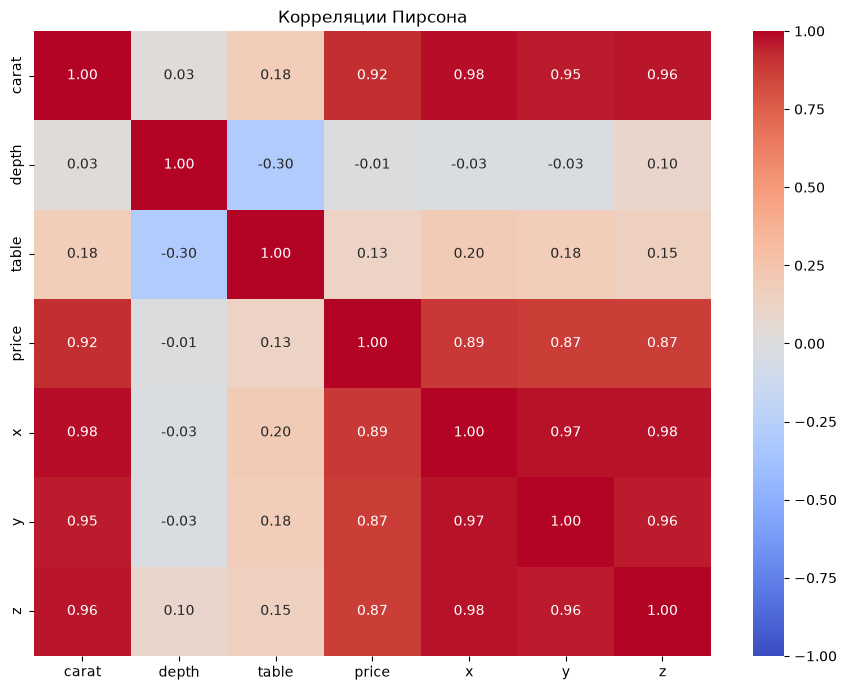

In [12]:
# ЗАДАНИЕ:
#          1. Постройте тепловую карту (heatmap) матрицы корреляций Пирсона
#          2. Постройте scatter plot для пары признаков с максимальной корреляцией
#             - Добавьте линию регрессии (sns.regplot)
#          3. Постройте pairplot для признаков ['carat', 'price', 'depth'] с цветовым разделением по 'cut'
plt.figure(figsize=(9, 7))

sns.heatmap(pearson, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)


plt.title('Корреляции Пирсона')
plt.tight_layout()
plt.show()

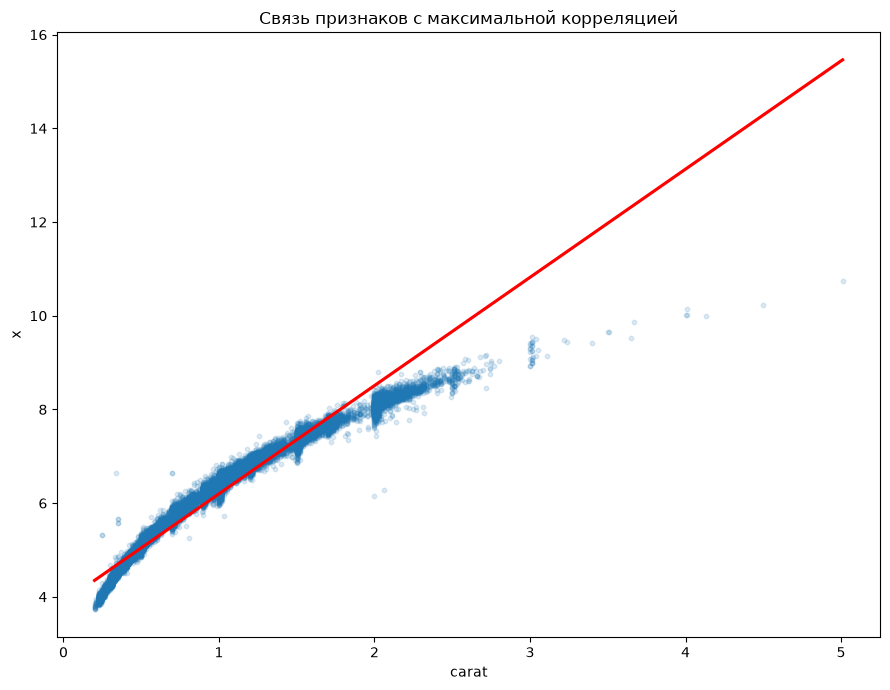

In [13]:
plt.figure(figsize=(9, 7))

sns.regplot(data=diamonds, x=first, y=second, scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'}, ci=None)

plt.xlabel(first)
plt.ylabel(second)
plt.title('Связь признаков с максимальной корреляцией')
plt.tight_layout()
plt.show()

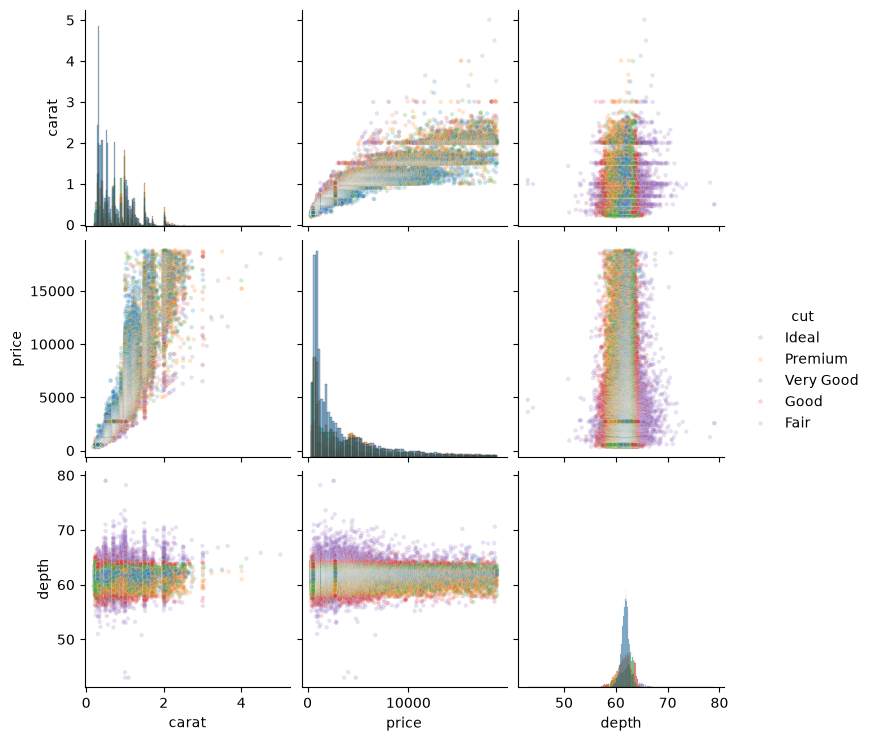

In [14]:
a = sns.pairplot(data=diamonds, vars=['carat', 'price', 'depth'], hue='cut', diag_kind='hist', plot_kws={'alpha': 0.2, 's': 10})

plt.show()

Видно сильную связь массы с размером и ценой. Зависимость длины от массы имеет изгиб, поэтому линейная модель описывает её не полностью. Цена растёт с массой, но камни одинаковой массы могут стоить по-разному.

### Дополнительное задание (1+ pt)

Проанализируйте влияние категориального признака `cut` (качество огранки) на распределение цены бриллиантов.

,count,mean_price,median_price,mean_carat
cut,,,,
Ideal,21548,3456.94,1809.5,0.70
Premium,13780,4579.68,3182.0,0.89
Very Good,12081,3981.66,2647.0,0.81
Good,4902,3926.40,3050.5,0.85
Fair,1609,4357.50,3282.0,1.05


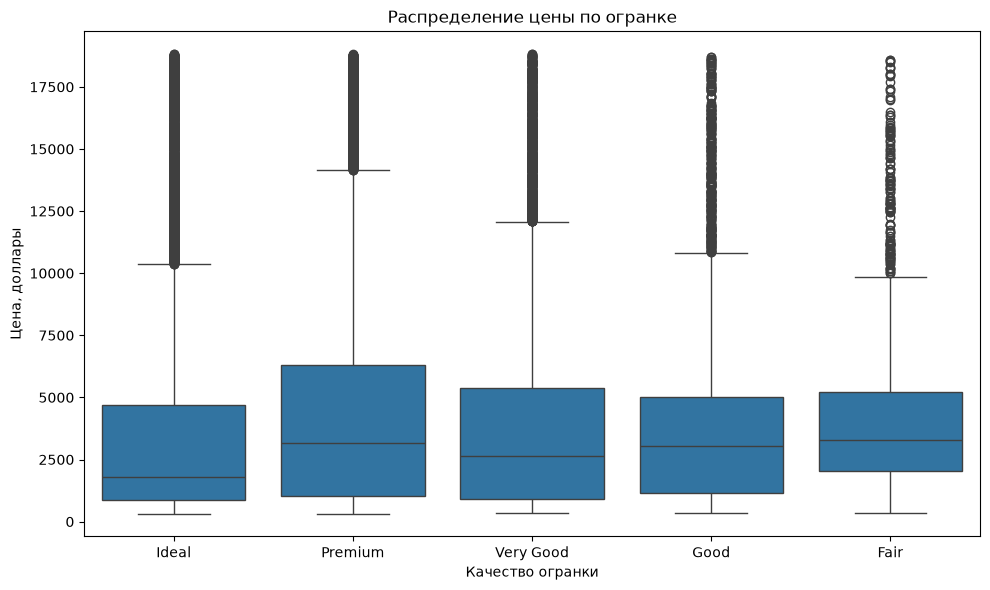

In [15]:
cut_stats = diamonds.groupby('cut', observed=True).agg(
    count=('price', 'size'), mean_price=('price', 'mean'),
    median_price=('price', 'median'), mean_carat=('carat', 'mean')
)
display(cut_stats.round(2))
plt.figure(figsize=(10, 6))
sns.boxplot(data=diamonds, x='cut', y='price')
plt.xlabel('Качество огранки')
plt.ylabel('Цена, доллары')
plt.title('Распределение цены по огранке')
plt.tight_layout()
plt.show()

Самая высокая средняя цена у Premium, самая низкая у Ideal. По этим данным нельзя сказать, что лучшая огранка сама по себе делает камень дороже: группы отличаются и по средней массе.

# Часть 2 (4 pt)

Теперь примените полученные навыки для анализа датасета **Palmer Penguins** — тоже стандартного датасета из `sns`. Этот датасет не такой большой, однако в нем можно найти интересные закономерности и больше узнать о пингвинчиках)

In [16]:
penguins = sns.load_dataset('penguins')

print(penguins.head())
print('-----------------------')
print(penguins.shape)
print('-----------------------')
penguins.info()

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
-----------------------
(344, 7)
-----------------------
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth

In [17]:
print(penguins.dtypes)
print('-----------------------')
print(penguins.isna().sum())
print('-----------------------')
print(penguins.isna().mean().mul(100).round(2))
print('-----------------------')
print(penguins.duplicated().sum())
print('-----------------------')
print(penguins.describe())

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object
-----------------------
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
-----------------------
species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
dtype: float64
-----------------------
0
-----------------------
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      342.000000     342.000000         342.000000   342.000000
mean        43.921930      17.151170         200.915205  4201.754386
std          5.459584       1.974793          14.061714   801.954536
min         32.100000      13.1

In [18]:
print(penguins[penguins.isna().any(axis=1)])

for column in ['species', 'island', 'sex']:
    print(f'\n{column}:')
    print(penguins[column].value_counts(dropna=False))

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
246  Gentoo     Biscoe            44.5           14.3              216.0   
286  Gentoo     Biscoe            46.2           14.4              214.0   
324  Gentoo     Biscoe            47.3           13.8              216.0   
336  Gentoo     Biscoe            44.5           15.7              217.0   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
8         3475.0  NaN  
9         4250.

In [19]:
numeric_columns = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

penguins_clean = penguins.dropna(subset=numeric_columns).copy()
penguins_with_sex = penguins_clean.dropna(subset=['sex']).copy()

Дубликатов нет, две строки без числовых измерений исключены. Для числового анализа остаётся 342 строки, для сравнения полов — 333. Строки без пола сохраняю там, где пол не нужен.

In [20]:
numeric = penguins_clean[numeric_columns]
stats = numeric.agg(['mean', 'median', 'std', 'var', 'skew', 'kurt']).T

stats['IQR'] = numeric.quantile(0.75) - numeric.quantile(0.25)
stats.round(3)

,mean,median,std,var,skew,kurt,IQR
bill_length_mm,43.922,44.45,5.460,29.807,0.053,-0.876,9.275
bill_depth_mm,17.151,17.30,1.975,3.900,-0.143,-0.907,3.100
flipper_length_mm,200.915,197.00,14.062,197.732,0.346,-0.984,23.000
body_mass_g,4201.754,4050.00,801.955,643131.077,0.470,-0.719,1200.000


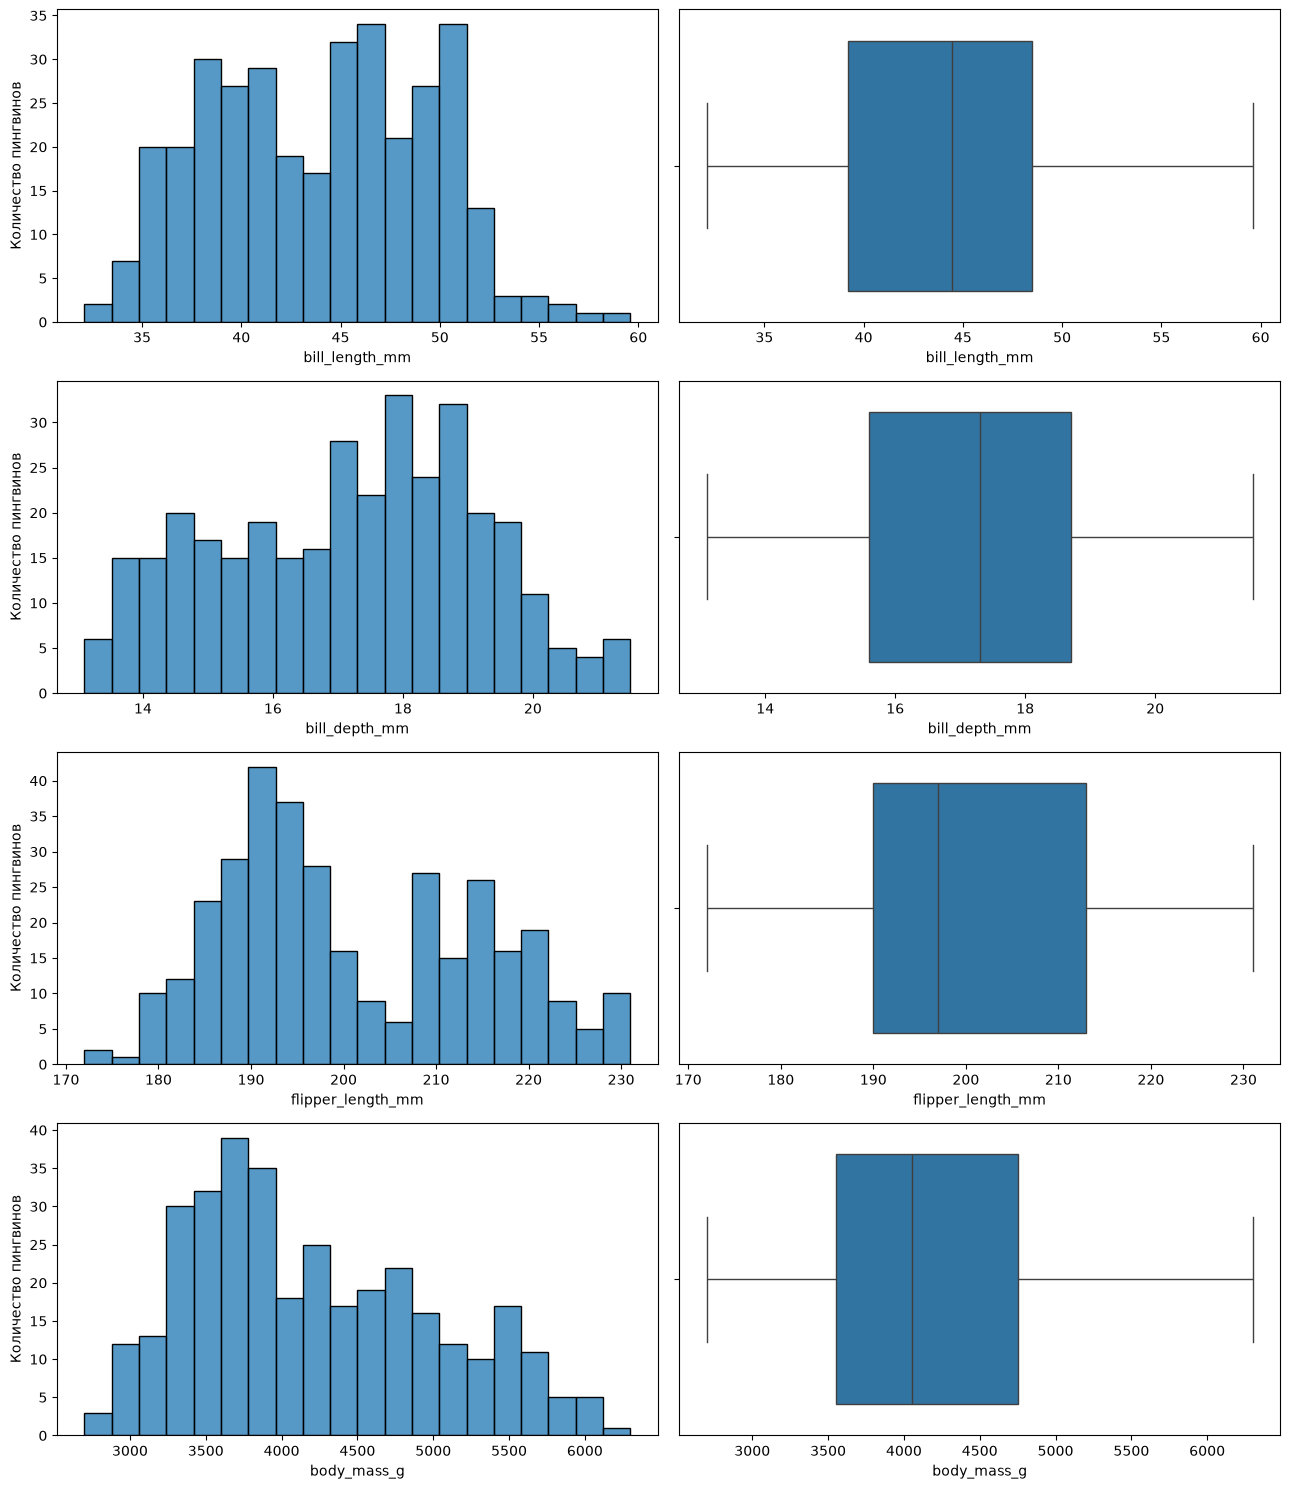

In [21]:

fig, axes = plt.subplots(4, 2, figsize=(13, 15))

for row, column in enumerate(numeric_columns):
    sns.histplot(
        data=penguins_clean, x=column,
        bins=20, ax=axes[row, 0]
    )
    sns.boxplot(
        data=penguins_clean, x=column,
        ax=axes[row, 1]
    )

    axes[row, 0].set_ylabel('Количество пингвинов')

plt.tight_layout()
plt.show()

Распределения неоднородны, особенно длина ласта и размеры клюва. У массы тела правая асимметрия. В общей выборке boxplot не показывает выбросов, но внутри отдельных видов они есть.

In [22]:
species_stats = (
    penguins_clean.groupby('species')[numeric_columns]
    .agg(['mean', 'median', 'std'])
)

print(species_stats.round(2))

          bill_length_mm              bill_depth_mm               \
                    mean median   std          mean median   std   
species                                                            
Adelie             38.79  38.80  2.66         18.35  18.40  1.22   
Chinstrap          48.83  49.55  3.34         18.42  18.45  1.14   
Gentoo             47.50  47.30  3.08         14.98  15.00  0.98   

          flipper_length_mm              body_mass_g                  
                       mean median   std        mean  median     std  
species                                                               
Adelie               189.95  190.0  6.54     3700.66  3700.0  458.57  
Chinstrap            195.82  196.0  7.13     3733.09  3700.0  384.34  
Gentoo               217.19  216.0  6.48     5076.02  5000.0  504.12  


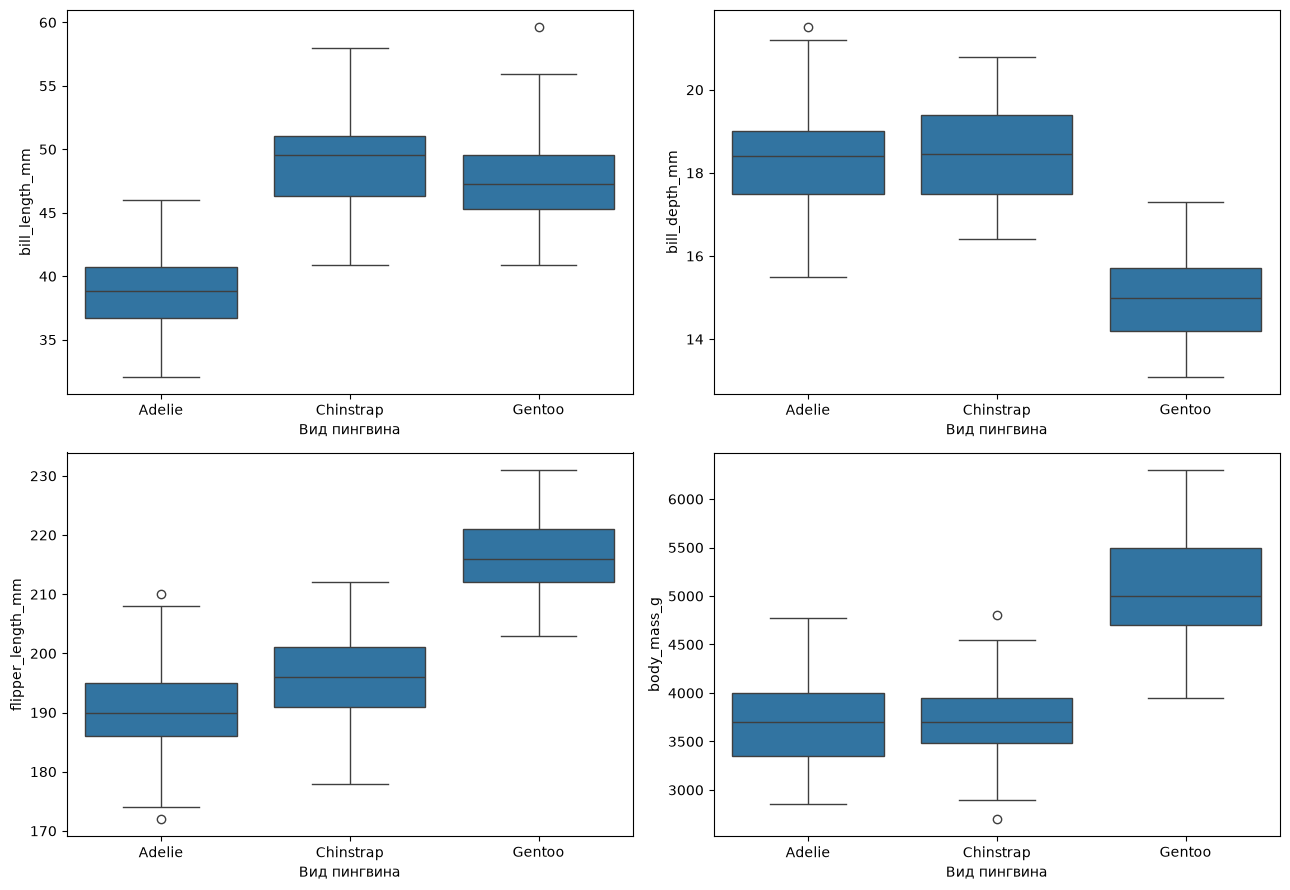

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(
        data=penguins_clean,
        x='species',
        y=column,
        ax=ax
    )
    ax.set_xlabel('Вид пингвина')

plt.tight_layout()
plt.show()

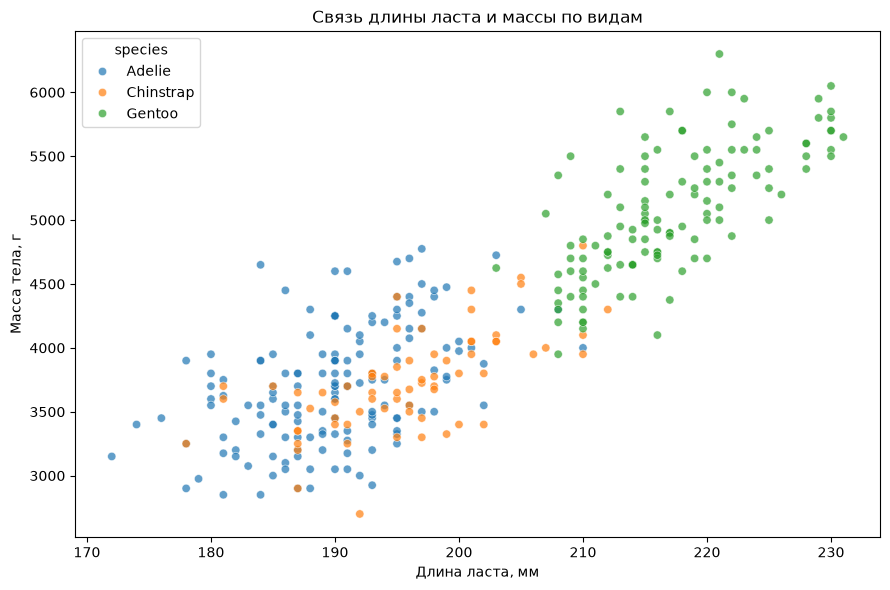

In [24]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=penguins_clean, x='flipper_length_mm', y='body_mass_g', hue='species', alpha=0.7)

plt.xlabel('Длина ласта, мм')
plt.ylabel('Масса тела, г')
plt.title('Связь длины ласта и массы по видам')
plt.tight_layout()
plt.show()

In [25]:
overall_corr = penguins_clean['flipper_length_mm'].corr(penguins_clean['body_mass_g'])

within_species_corr = (penguins_clean.groupby('species')[['flipper_length_mm', 'body_mass_g']].corr().xs('flipper_length_mm', level=1)['body_mass_g'])

print('Корреляция в общей выборке:', round(overall_corr, 3))
print('Корреляция внутри видов:')
print(within_species_corr.round(3))

Корреляция в общей выборке: 0.871
Корреляция внутри видов:
species
Adelie       0.468
Chinstrap    0.642
Gentoo       0.703
Name: body_mass_g, dtype: float64


Сравнение по видам показало, что неоднородность общих распределений частично объясняется различиями между группами. Gentoo отличаются большей массой и длиной ласта, но меньшей глубиной клюва. Общая корреляция длины ласта и массы равна 0.871, при этом внутри видов она ниже (от 0.468 до 0.703). Следовательно, сильная связь в объединенной выборке отражает как связь внутри видов, так и различия между ними.

In [26]:
sex_stats = (penguins_with_sex.groupby(['species', 'sex'])['body_mass_g'].agg(['count', 'mean', 'median', 'std']))

print(sex_stats.round(2))

                  count     mean  median     std
species   sex                                   
Adelie    Female     73  3368.84  3400.0  269.38
          Male       73  4043.49  4000.0  346.81
Chinstrap Female     34  3527.21  3550.0  285.33
          Male       34  3938.97  3950.0  362.14
Gentoo    Female     58  4679.74  4700.0  281.58
          Male       61  5484.84  5500.0  313.16


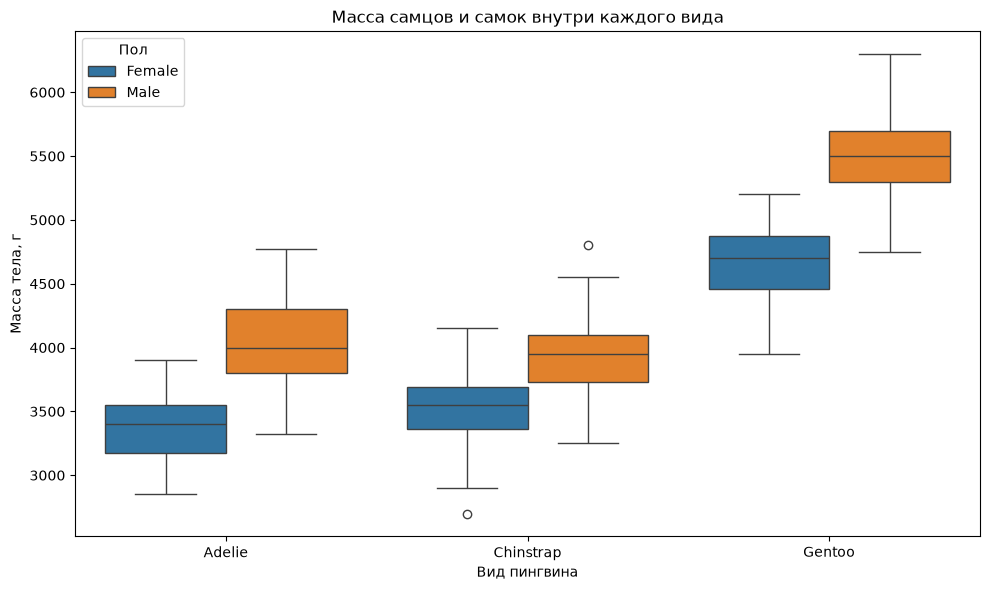

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=penguins_with_sex, x='species', y='body_mass_g', hue='sex', hue_order=['Female', 'Male'])

plt.xlabel('Вид пингвина')
plt.ylabel('Масса тела, г')
plt.title('Масса самцов и самок внутри каждого вида')
plt.legend(title='Пол')
plt.tight_layout()
plt.show()

In [28]:
mean_mass = (penguins_with_sex.groupby(['species', 'sex'])['body_mass_g'].mean().unstack('sex'))

mean_mass['Разница'] = mean_mass['Male'] - mean_mass['Female']
mean_mass['Разница в % '] = mean_mass['Разница'] / mean_mass['Female'] * 100
display(mean_mass.round(2))

sex,Female,Male,Разница,Разница в %
species,,,,
Adelie,3368.84,4043.49,674.66,20.03
Chinstrap,3527.21,3938.97,411.76,11.67
Gentoo,4679.74,5484.84,805.09,17.20


Самцы в среднем тяжелее самок внутри каждого вида. Наибольшая разница достигается у Gentoo - 805 грамм, а в процентном отношении у Adelie, там 20%

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0


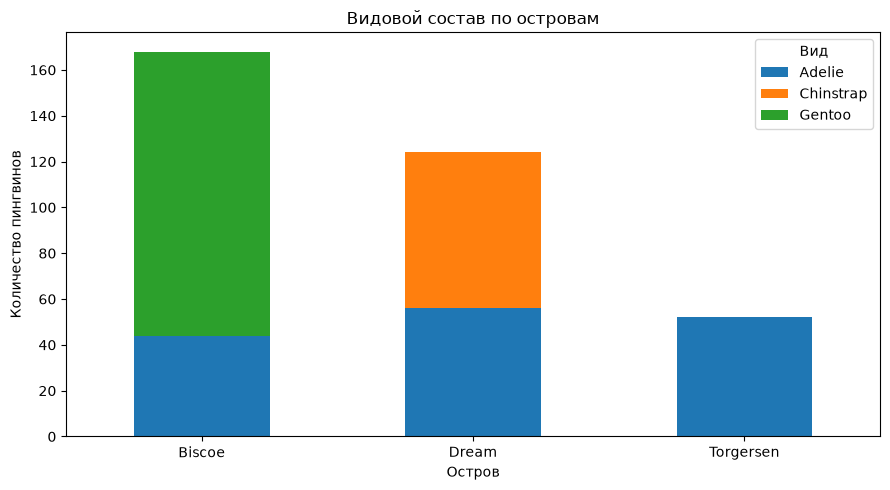

In [29]:
island_species = pd.crosstab(penguins['island'], penguins['species'])

print(island_species)

island_species.plot(kind='bar', stacked=True, figsize=(9, 5))

plt.xlabel('Остров')
plt.ylabel('Количество пингвинов')
plt.title('Видовой состав по островам')
plt.xticks(rotation=0)
plt.legend(title='Вид')
plt.tight_layout()
plt.show()

           count     mean  median
island                           
Biscoe       167  4716.02  4775.0
Dream        124  3712.90  3687.5
Torgersen     51  3706.37  3700.0
           count     mean  median
island                           
Biscoe        44  3709.66  3750.0
Dream         56  3688.39  3575.0
Torgersen     51  3706.37  3700.0


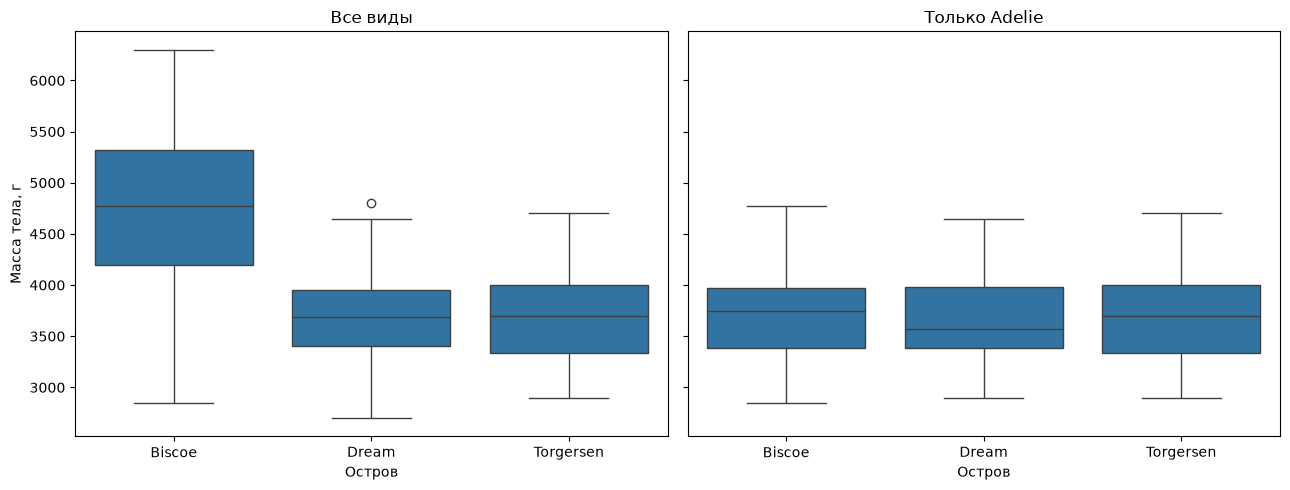

In [30]:
adelie = penguins_clean[penguins_clean['species'] == 'Adelie']

print(penguins_clean.groupby('island')['body_mass_g'].agg(['count', 'mean', 'median']).round(2))

print(adelie.groupby('island')['body_mass_g'].agg(['count', 'mean', 'median']).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
island_order = ['Biscoe', 'Dream', 'Torgersen']

sns.boxplot(data=penguins_clean, x='island', y='body_mass_g', order=island_order, ax=axes[0])

sns.boxplot(data=adelie, x='island', y='body_mass_g', order=island_order, ax=axes[1])

axes[0].set_title('Все виды')
axes[1].set_title('Только Adelie')
for ax in axes:
    ax.set_xlabel('Остров')
    ax.set_ylabel('Масса тела, г')
plt.tight_layout()
plt.show()

На Biscoe средняя масса 4716 г, на Dream — 3713 г, на Torgersen — 3706 г. Для Adelie отдельно значения близки: 3710, 3688 и 3706 г. Разница между островами связана с видовым составом, а не доказывает влияние острова на массу.

# Выводы

1. Общая корреляция длины ласта и массы — 0.871, внутри видов — от 0.468 до 0.703. Общий коэффициент отражает и связь внутри видов, и различия между ними.
2. Самцы тяжелее у всех видов. Максимальная абсолютная разница у Gentoo — 805 г, относительная у Adelie — 20%.
3. Разрыв средней массы между островами около 1000 г почти исчезает при сравнении только Adelie. При сравнении островов важно учитывать вид.

***
**ЗАДАНИЕ:** Проведите полный EDA датасета penguins.  
Для это проведите
* базовое **знакомство и чистку** данных (обосновывайте ваши действия),
* **одномерный анализ** всех признаков,
* **двумерный анализ** (не только корреляции, но и распределение при значениях других признаков),
* а также **сформулируйте 3 неочевидных вывода**, подкреплённых **статистикой/визуализацией**.

**УДОСТОВЕРЬТЕСЬ, ЧТО ВСЕ ВАШИ ВЫВОДЫ И КОД ОФОРМЛЕНЫ ТАК, ЧТОБЫ ЛЕГКО МОЖНО БЫЛО ПОНЯТЬ, К ЧЕМУ ОНИ ОТНОСЯТСЯ**  
**НЕ ЗАБУДЬТЕ ПЕРЕЗАПУСТИТЬ НОУТБУК ТАК, ЧТОБЫ ВСЕ ЯЧЕЙКИ БЫЛИ ЗАПУЩЕНЫ ПОДРЯД, НАЧИНАЯ С [1]**